<a href="https://colab.research.google.com/github/nakshath241501126/deep-learning/blob/main/mini_proj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import gzip
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Setup completed successfully!")

TensorFlow version: 2.21.0
Setup completed successfully!


In [2]:
# Download Fashion-MNIST automatically
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


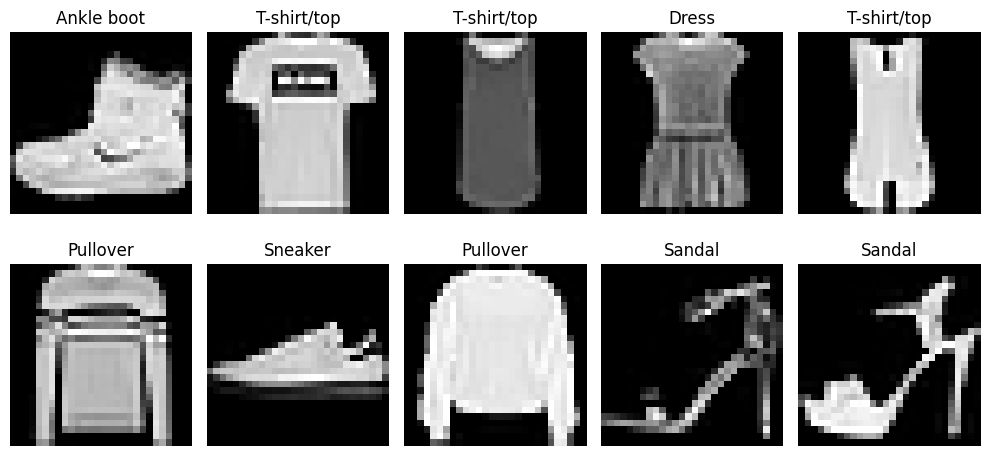

In [3]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Normalize pixel values from 0–255 to 0–1
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add a channel dimension for the CNN
x_train_full = x_train_full[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training data shape:", x_train_full.shape)
print("Test data shape:", x_test.shape)
print("Minimum pixel value:", x_train_full.min())
print("Maximum pixel value:", x_train_full.max())

Training data shape: (60000, 28, 28, 1)
Test data shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Test images:", x_test.shape)

Training images: (48000, 28, 28, 1)
Validation images: (12000, 28, 28, 1)
Test images: (10000, 28, 28, 1)


In [6]:
def build_baseline():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),

        layers.Dense(10, activation="softmax")
    ], name="baseline_mlp")

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


baseline_model = build_baseline()

baseline_model.summary()

Model: "baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
EPOCHS = 10
BATCH_SIZE = 128

hist_base = baseline_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2
)

Epoch 1/10
375/375 - 3s - 9ms/step - accuracy: 0.7994 - loss: 0.5867 - val_accuracy: 0.8187 - val_loss: 0.4976
Epoch 2/10
375/375 - 2s - 5ms/step - accuracy: 0.8491 - loss: 0.4265 - val_accuracy: 0.8363 - val_loss: 0.4510
Epoch 3/10
375/375 - 2s - 5ms/step - accuracy: 0.8634 - loss: 0.3836 - val_accuracy: 0.8468 - val_loss: 0.4208
Epoch 4/10
375/375 - 3s - 7ms/step - accuracy: 0.8715 - loss: 0.3571 - val_accuracy: 0.8584 - val_loss: 0.3945
Epoch 5/10
375/375 - 3s - 8ms/step - accuracy: 0.8791 - loss: 0.3371 - val_accuracy: 0.8710 - val_loss: 0.3701
Epoch 6/10
375/375 - 3s - 7ms/step - accuracy: 0.8842 - loss: 0.3207 - val_accuracy: 0.8767 - val_loss: 0.3505
Epoch 7/10
375/375 - 4s - 11ms/step - accuracy: 0.8890 - loss: 0.3068 - val_accuracy: 0.8802 - val_loss: 0.3408
Epoch 8/10
375/375 - 2s - 5ms/step - accuracy: 0.8928 - loss: 0.2948 - val_accuracy: 0.8834 - val_loss: 0.3321
Epoch 9/10
375/375 - 2s - 5ms/step - accuracy: 0.8965 - loss: 0.2841 - val_accuracy: 0.8848 - val_loss: 0.3266


In [8]:
def build_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, (3, 3),
                      activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3),
                      activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),

        layers.Dense(10, activation="softmax")
    ], name="improved_cnn")

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn_model = build_cnn()

cnn_model.summary()

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
hist_cnn = cnn_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=2
)

Epoch 1/10
375/375 - 51s - 136ms/step - accuracy: 0.8396 - loss: 0.4469 - val_accuracy: 0.8842 - val_loss: 0.3217
Epoch 2/10
375/375 - 52s - 139ms/step - accuracy: 0.8737 - loss: 0.3502 - val_accuracy: 0.8971 - val_loss: 0.2866
Epoch 3/10
375/375 - 82s - 218ms/step - accuracy: 0.8884 - loss: 0.3097 - val_accuracy: 0.9057 - val_loss: 0.2656
Epoch 4/10
375/375 - 52s - 139ms/step - accuracy: 0.8986 - loss: 0.2795 - val_accuracy: 0.9087 - val_loss: 0.2540
Epoch 5/10
375/375 - 68s - 180ms/step - accuracy: 0.9064 - loss: 0.2572 - val_accuracy: 0.9143 - val_loss: 0.2449
Epoch 6/10
375/375 - 51s - 136ms/step - accuracy: 0.9129 - loss: 0.2395 - val_accuracy: 0.9159 - val_loss: 0.2376
Epoch 7/10
375/375 - 82s - 219ms/step - accuracy: 0.9179 - loss: 0.2235 - val_accuracy: 0.9197 - val_loss: 0.2274
Epoch 8/10
375/375 - 81s - 216ms/step - accuracy: 0.9230 - loss: 0.2089 - val_accuracy: 0.9211 - val_loss: 0.2261
Epoch 9/10
375/375 - 82s - 220ms/step - accuracy: 0.9290 - loss: 0.1945 - val_accuracy: 

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

def evaluate(model, name):
    # Predict the classes of unseen test images
    probabilities = model.predict(x_test, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    # Calculate evaluation metrics
    print(f"\n===== {name} =====")

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ))
    print("Recall:", recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ))
    print("F1-score:", f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=class_names,
        zero_division=0
    ))

    return y_pred, confusion_matrix(y_test, y_pred)


base_pred, base_cm = evaluate(
    baseline_model, "Baseline Neural Network"
)

cnn_pred, cnn_cm = evaluate(
    cnn_model, "Convolutional Neural Network (CNN)"
)


===== Baseline Neural Network =====
Accuracy: 0.8758
Precision: 0.8791848799459572
Recall: 0.8758000000000001
F1-score: 0.8769375166840453

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.78      0.82      1000
     Trouser       0.98      0.97      0.98      1000
    Pullover       0.78      0.79      0.79      1000
       Dress       0.90      0.86      0.88      1000
        Coat       0.78      0.82      0.80      1000
      Sandal       0.97      0.95      0.96      1000
       Shirt       0.65      0.71      0.68      1000
     Sneaker       0.92      0.97      0.94      1000
         Bag       0.98      0.96      0.97      1000
  Ankle boot       0.97      0.94      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000


===== Convolutional Neural Network (CNN) =====
Accuracy: 0.9179
Precision: 0

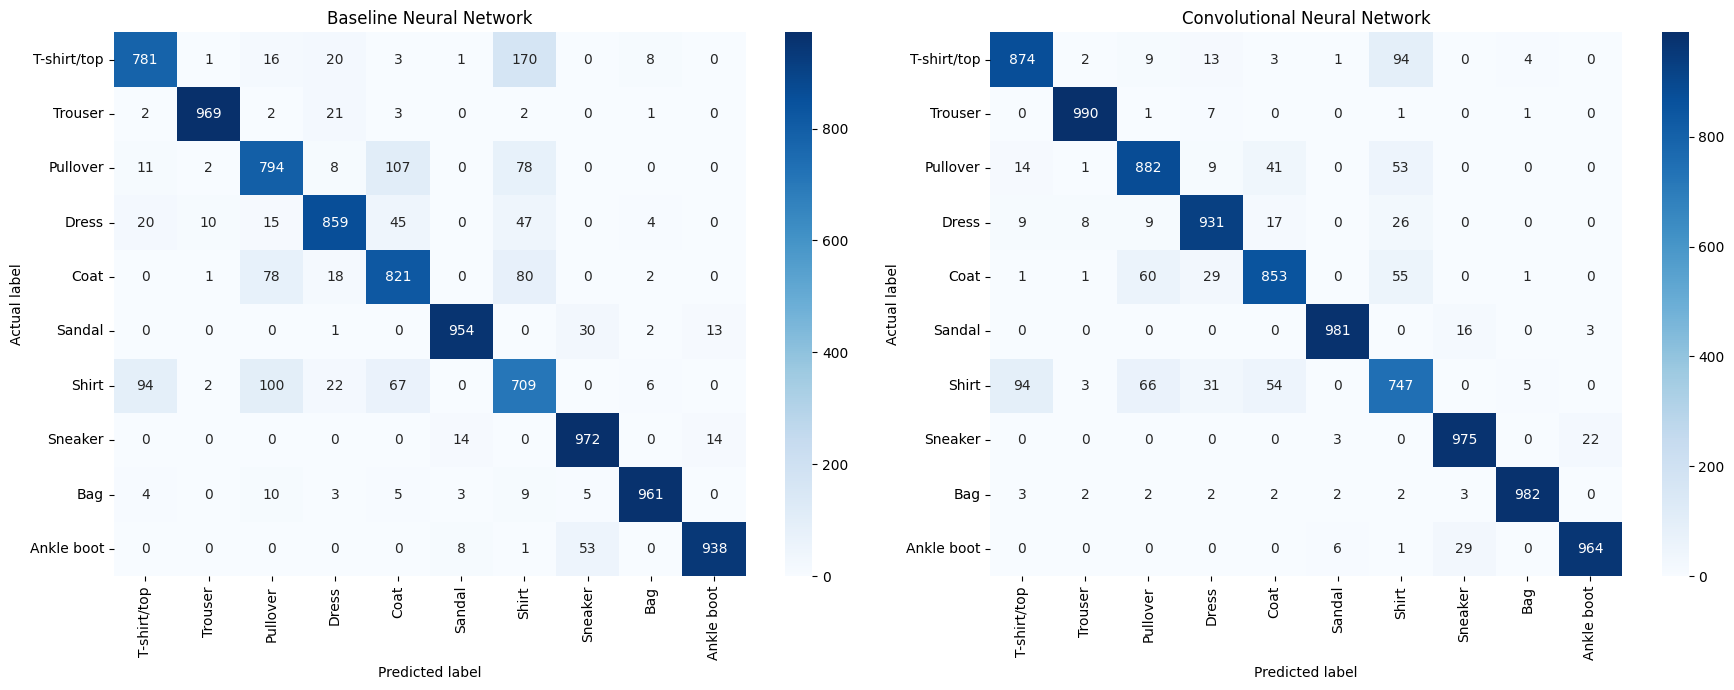

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    base_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)
axes[0].set_title("Baseline Neural Network")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("Actual label")

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)
axes[1].set_title("Convolutional Neural Network")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("Actual label")

plt.tight_layout()
plt.show()

Metric          Baseline         CNN
Accuracy          0.8758      0.9179
Precision         0.8792      0.9177
Recall            0.8758      0.9179
F1-score          0.8769      0.9177


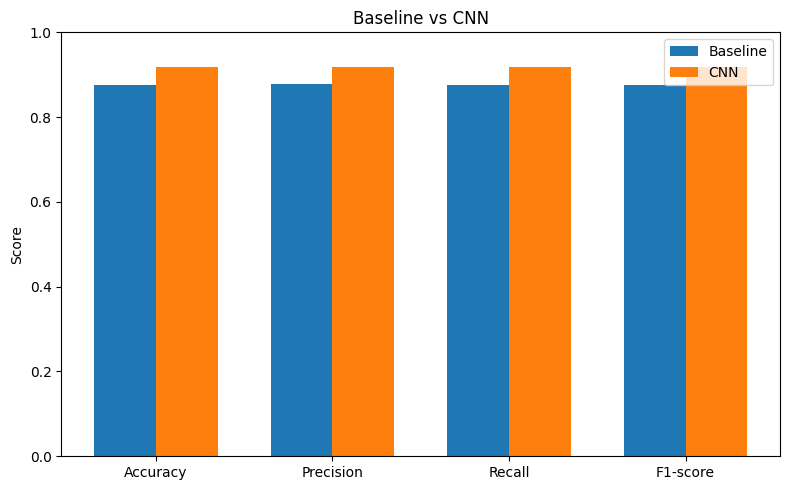

In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

base_scores = [
    accuracy_score(y_test, base_pred),
    precision_score(y_test, base_pred, average="macro", zero_division=0),
    recall_score(y_test, base_pred, average="macro", zero_division=0),
    f1_score(y_test, base_pred, average="macro", zero_division=0)
]

cnn_scores = [
    accuracy_score(y_test, cnn_pred),
    precision_score(y_test, cnn_pred, average="macro", zero_division=0),
    recall_score(y_test, cnn_pred, average="macro", zero_division=0),
    f1_score(y_test, cnn_pred, average="macro", zero_division=0)
]

print(f"{'Metric':<12}{'Baseline':>12}{'CNN':>12}")
for metric, base, cnn in zip(metrics, base_scores, cnn_scores):
    print(f"{metric:<12}{base:>12.4f}{cnn:>12.4f}")

plt.figure(figsize=(8, 5))
x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width / 2, base_scores, width, label="Baseline")
plt.bar(x + width / 2, cnn_scores, width, label="CNN")

plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Baseline vs CNN")
plt.legend()
plt.tight_layout()
plt.show()

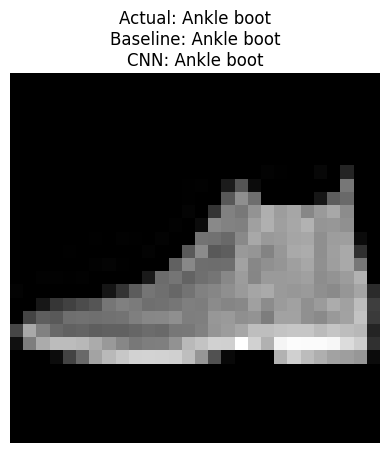

Actual class: Ankle boot


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [15]:
import matplotlib.pyplot as plt
import numpy as np

i = 0  # Change this number to test another image

image = x_test[i:i+1]

baseline_probs = baseline_model.predict(image, verbose=0)[0]
cnn_probs = cnn_model.predict(image, verbose=0)[0]

baseline_label = np.argmax(baseline_probs)
cnn_label = np.argmax(cnn_probs)

plt.imshow(x_test[i].squeeze(), cmap="gray")
plt.title(
    f"Actual: {class_names[y_test[i]]}\n"
    f"Baseline: {class_names[baseline_label]}\n"
    f"CNN: {class_names[cnn_label]}"
)
plt.axis("off")
plt.show()

print("Actual class:", class_names[y_test[i]])
print

In [16]:
baseline_model.save("baseline_model.keras")
cnn_model.save("fashion_cnn_model.keras")

print("Both models saved successfully!")

Both models saved successfully!


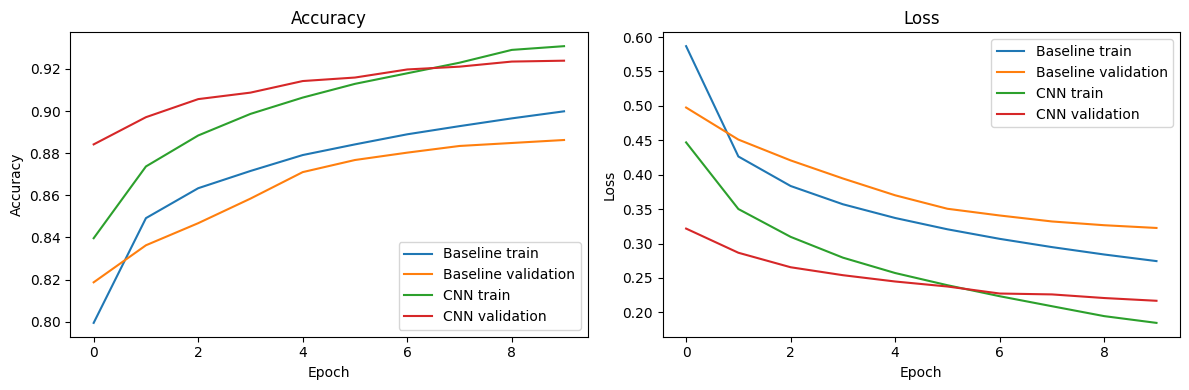

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy graph
axes[0].plot(hist_base.history["accuracy"], label="Baseline train")
axes[0].plot(hist_base.history["val_accuracy"], label="Baseline validation")
axes[0].plot(hist_cnn.history["accuracy"], label="CNN train")
axes[0].plot(hist_cnn.history["val_accuracy"], label="CNN validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss graph
axes[1].plot(hist_base.history["loss"], label="Baseline train")
axes[1].plot(hist_base.history["val_loss"], label="Baseline validation")
axes[1].plot(hist_cnn.history["loss"], label="CNN train")
axes[1].plot(hist_cnn.history["val_loss"], label="CNN validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_performance.png", dpi=200, bbox_inches="tight")
plt.show()